# SA-1B (Segment Anything 1-Billion) Exploration

Overview of Meta AI's Segment Anything 1-Billion dataset for class-agnostic segmentation.

## Dataset Overview & Schema

- **Source Used for Analysis:** Hugging Face mirror [`hdtech/SA-1B`](https://huggingface.co/datasets/hdtech/SA-1B) (streaming split `"train"`)
- **Where to Get Full Dataset Later:** Official Meta AI portal: [https://ai.meta.com/datasets/segment-anything/](https://ai.meta.com/datasets/segment-anything/) or Hugging Face [https://huggingface.co/datasets/hdtech/SA-1B](https://huggingface.co/datasets/hdtech/SA-1B)
- **Full Dataset Size:** **~10 to 11 Terabytes (TB)** total across 1,000 shards (11M images, 1.1B masks; ~10–11 GB per shard)
- **Use in Project:** Reference foundation dataset for SAM (Segment Anything Model)

### Dataset Schema
| Field | Type | Description |
| :--- | :--- | :--- |
| `image` | `PIL.Image` | High-resolution photographic image (RGB). |
| `label` | `str` / `int` | Shard part identifier (e.g., `'SA-1B-Part-000000'`). |
| `annotations` | `list[dict]` | Class-agnostic segmentation masks for all objects: |
| ↳ `bbox` | `list[float]` | Bounding box in `[x, y, w, h]` format. |
| ↳ `area` | `int` | Mask area in pixels. |
| ↳ `segmentation` | `dict` | Run-Length Encoded (RLE) mask (`counts`, `size`). |
| ↳ `point_coords` | `list[list[float]]` | Foreground click point coordinates inside the mask. |
| ↳ `stability_score` | `float` | SAM model mask stability/confidence score ($0.0$ to $1.0$). |


### 1. Load dataset samples (streaming mode)


In [ ]:
from datasets import load_dataset, Value
from PIL import UnidentifiedImageError

part_names = [
    "SA-1B-Part-000000",
    "SA-1B-Part-000001",
    "SA-1B-Part-000002",
    "SA-1B-Part-000003",
    "SA-1B-Part-000004",
    "SA-1B-Part-000995",
    "SA-1B-Part-000996",
    "SA-1B-Part-000997",
    "SA-1B-Part-000998",
    "SA-1B-Part-000999",
]
id2label = dict(enumerate(part_names))

ds_stream = load_dataset(
    "hdtech/SA-1B",
    streaming=True,
    split="train",
).cast_column("label", Value("string"))

# Create an iterator to manually fetch items and bypass decode exceptions if needed
stream_iter = iter(ds_stream)
count = 0
max_samples = 10

while count < max_samples:
    try:
        row = next(stream_iter)
        raw_label = row["label"]

        if isinstance(raw_label, int):
            label_str = id2label.get(raw_label, str(raw_label))
        elif isinstance(raw_label, str) and raw_label.isdigit() and int(raw_label) in id2label:
            label_str = id2label[int(raw_label)]
        else:
            label_str = str(raw_label)

        img = row["image"]
        print(f"Sample {count}: label={label_str}, size={img.size}")
        count += 1
    except StopIteration:
        break
    except (UnidentifiedImageError, ValueError) as e:
        print(f"Skipping invalid entry due to error: {e}")
        continue

Sample 0: label=SA-1B@2d44f4fc509826413467344f56df88c8cb0fd239, size=(1500, 2060)
Skipping invalid entry due to error: cannot identify image file <_io.BytesIO object at 0x793a49aa5760>


In [ ]:
ds_stream

IterableDataset({
    features: ['image', 'label'],
    num_shards: 1
})

Features: {'image': Image(mode=None, decode=True), 'label': Value('string')}
Num shards: 1
Keys: ['image', 'label']
Label: SA-1B@2d44f4fc509826413467344f56df88c8cb0fd239 <class 'str'>


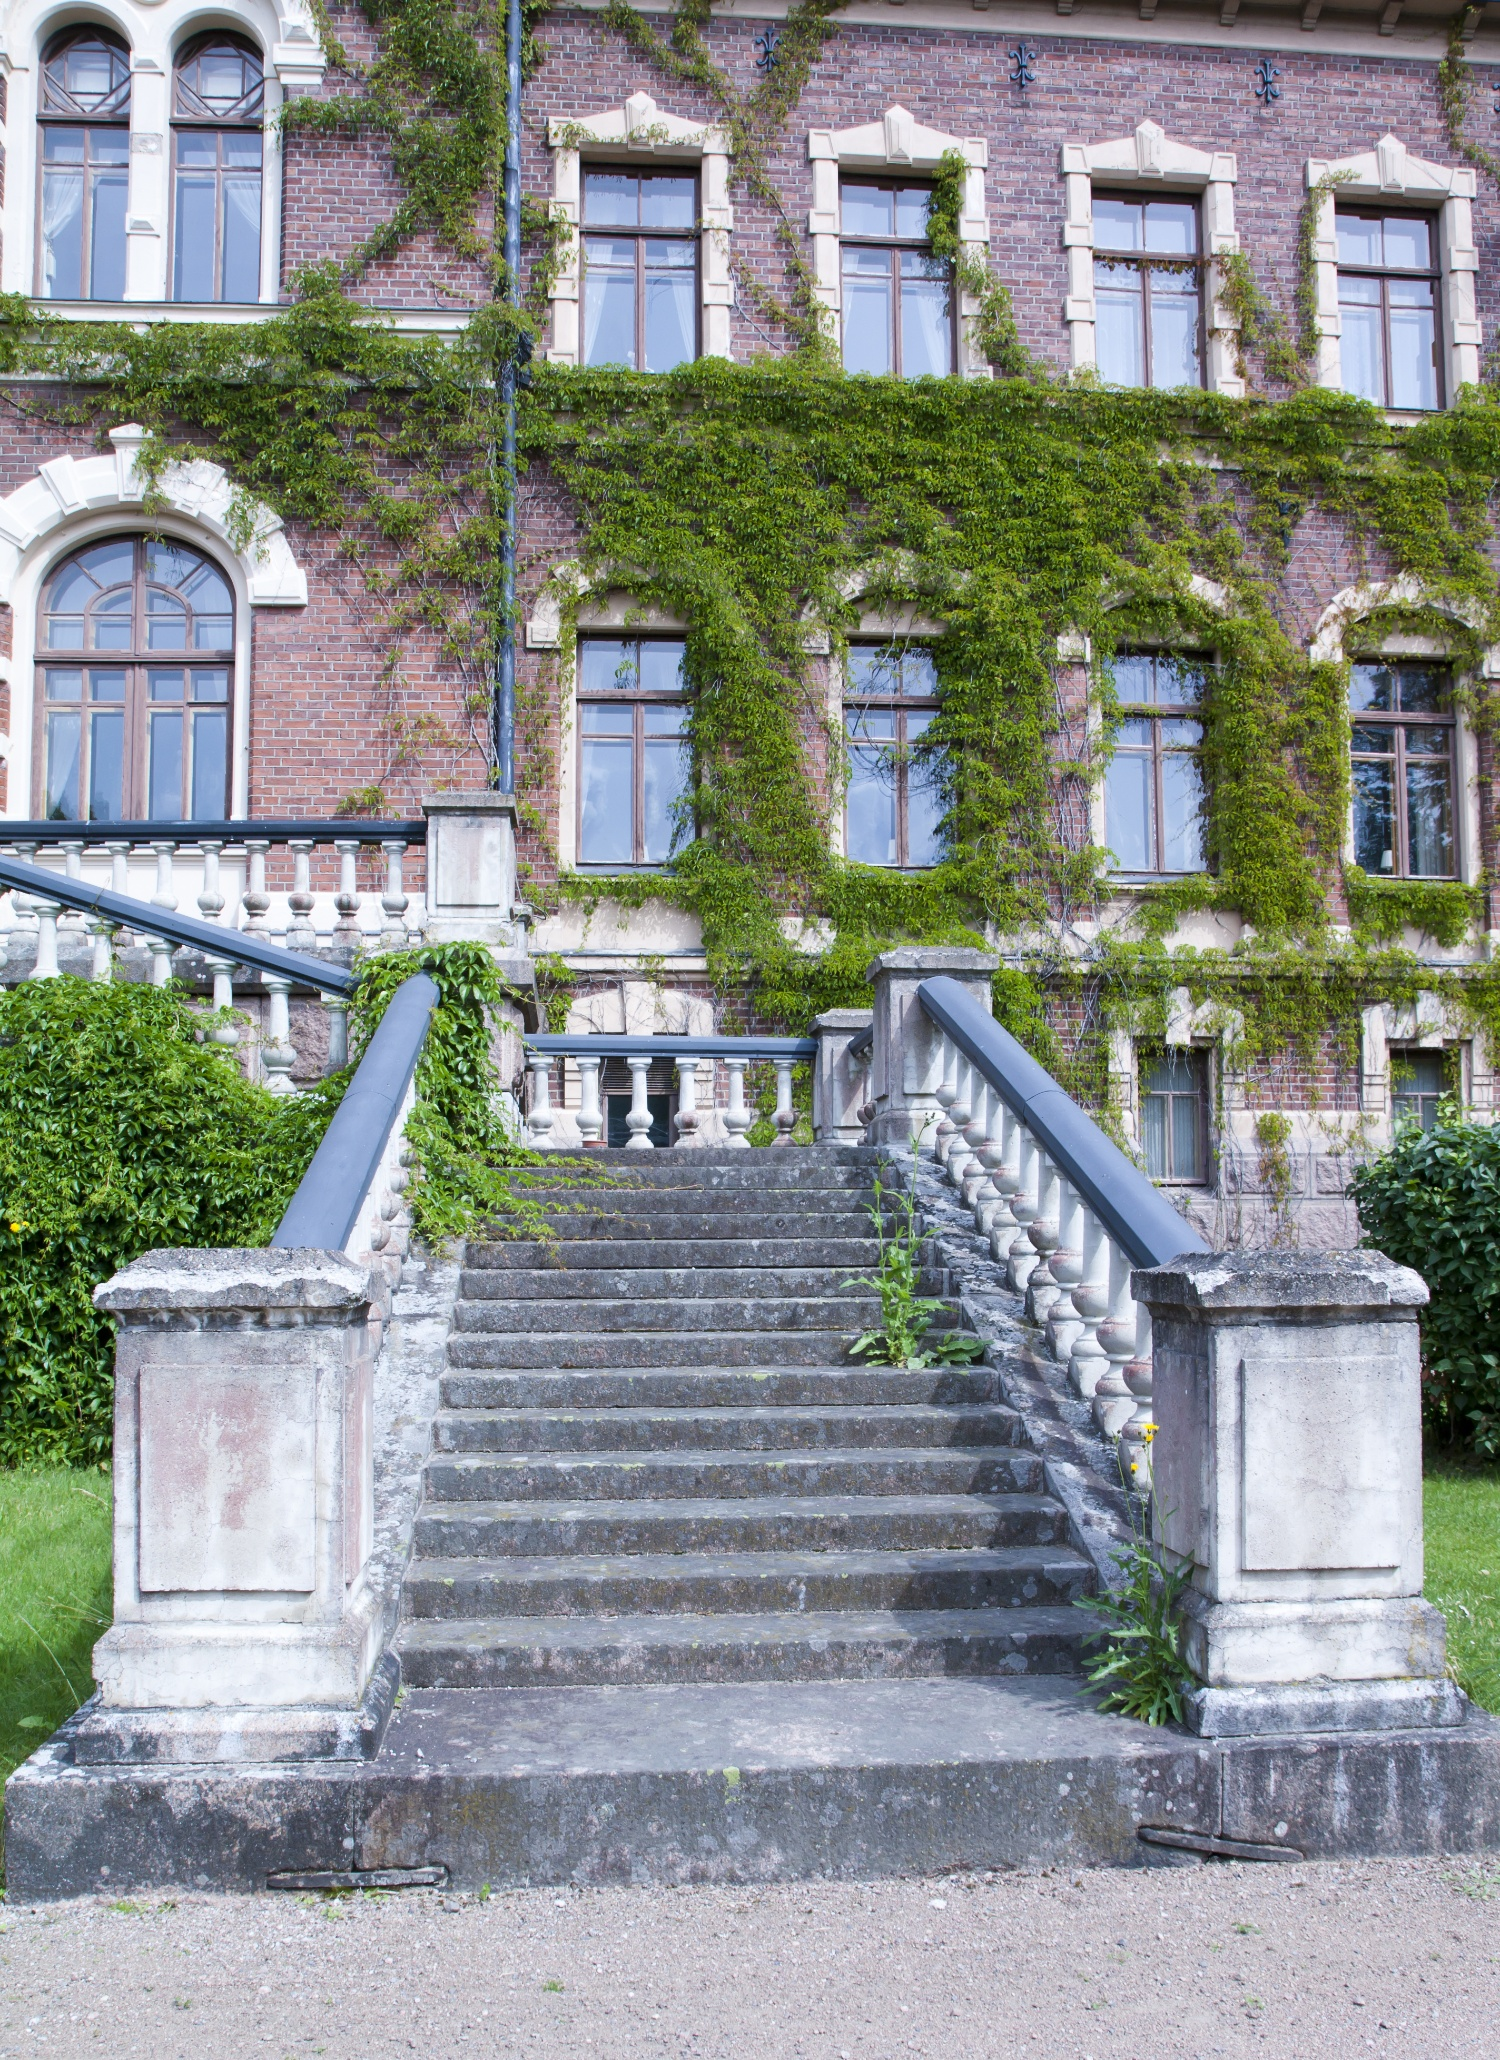

In [ ]:
print("Features:", ds_stream.features)
print("Num shards:", ds_stream.num_shards)

row = next(iter(ds_stream))
print("Keys:", list(row.keys()))
print("Label:", row["label"], type(row["label"]))
row["image"]